# Vectorial imaging: lines and spaces with s, p and unpolarized light

In optical lithography a projection lens images a mask with lines and
spaces onto a wafer. The smallest half pitch is
$\mathrm{hp} = k_1\,\lambda/\mathrm{NA}$; today's ArF immersion scanners
($\lambda = 193\,$nm, water with $n = 1.437$, NA 1.35) print lines with
$k_1 \approx 0.28$, i.e. a half pitch of 40 nm. At such a numerical aperture
the interfering diffraction orders travel at angles of up to 70° in the
water, and it matters a lot how they are polarized:

- **TE (s)**: the electric field is perpendicular to the plane of incidence,
  i.e. parallel to the lines. All orders have parallel fields and interfere
  with full contrast.
- **TM (p)**: the field lies in the plane of incidence. Two orders at
  $\pm\theta$ have fields that enclose the angle $2\theta$; they interfere with the
  contrast $|\cos 2\theta|$, which vanishes at 45° and reverses beyond.
- **unpolarized**: the incoherent mean of both.

This notebook uses the lithography toolbox `pyoptics.litho`: Abbe's method
(sum over mutually incoherent source points), a thin mask, an aplanatic
projection lens that rotates the polarization of every diffraction order
(`propagators.aplanatic_rotation()`, see notebook 02), and the polarization
helpers of `pyoptics.polarization` (TE/TM bases, partially polarized light,
intensity in the preferred state IPS). Notebook 32 shows the rest of the
toolbox (more sources and masks, mask and wafer stacks, aberrations,
apodization, and KrF lithography at 248 nm with its material data).

| Part of `pyoptics.litho` | used here for |
|---|---|
| `Illumination.conventional/annular/dipole/quasar/dipole_for_pitch(..., polarization=, dop=)` | sources with x, y, TE, TM, unpolarized or partially polarized light |
| `MaskLayout.lines_spaces/contact_holes`, `ThinMask.binary/att_psm` | the masks (thin mask approximation) |
| `Projector(NA, wl, n, vectorial=)` | immersion lens, vectorial or scalar model (aberrations and apodization: notebook 32) |
| `LithoSimulation(layout, stack, illumination, projector).image/cut/nils/fem` | images (normalized to the open frame), NILS, focus-exposure matrices |
| `metrics.contrast/nils/process_window/el_dof` | image metrics and process windows |
| `litho.plot.plot_source/plot_pupil_fill/plot_image/plot_bossung/plot_process_window` | figures |

All lengths are image-side values in nm. Convention:
$\exp(i(\mathbf{k}\cdot\mathbf{r} - \omega t))$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyoptics.litho import Illumination, MaskLayout, ThinMask, Projector, LithoSimulation, metrics
from pyoptics.litho.plot import (plot_source, plot_pupil_fill, plot_image, plot_bossung,
                                 plot_process_window)
from pyoptics.vectorial_imaging import two_beam_contrast, image_1d, lines_spaces_orders
from pyoptics.polarization import IPS
from pyoptics.polarization.jones import J_V

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})

wl = 193.0          # ArF
n_w = 1.437         # water at 193 nm
NA = 1.35
water = Projector(NA, wl, n_w)
POLS = [("y", "TE (y, along the lines)", "C0"), ("x", "TM (x, across the lines)", "C3"),
        ("unpolarized", "unpolarized", "C2")]

## 1. Two-beam interference

The simplest image: two plane waves of equal amplitude at $\pm\theta$ (in the
medium). Their intensity pattern $I \propto 1 + V\cos(2k\sin\theta\,x)$ has the
period $\lambda/(2n\sin\theta)$ and the contrast $V = 1$ (TE),
$|\cos 2\theta|$ (TM) and $\cos^2\theta$ (unpolarized). For two beams that pass
symmetrically through the pupil of an immersion lens, the half pitch is
$\mathrm{hp} = \lambda/(4 n\sin\theta) = \lambda/(4\,\mathrm{NA_{eff}})$, i.e.
$k_1 = \mathrm{NA}/(4\,\mathrm{NA_{eff}})$ when both beams use the full pupil.

Numerically the two beams are the orders $\pm1$ of a chromeless phase
grating (`ThinMask(-1.0)`, lines and spaces 1:1 with the transmissions
$-1$ and $1$: no zeroth order, the orders $\pm3$ do not pass the pupil) of
the pitch $4\,\mathrm{hp}$ under coherent normal incidence.

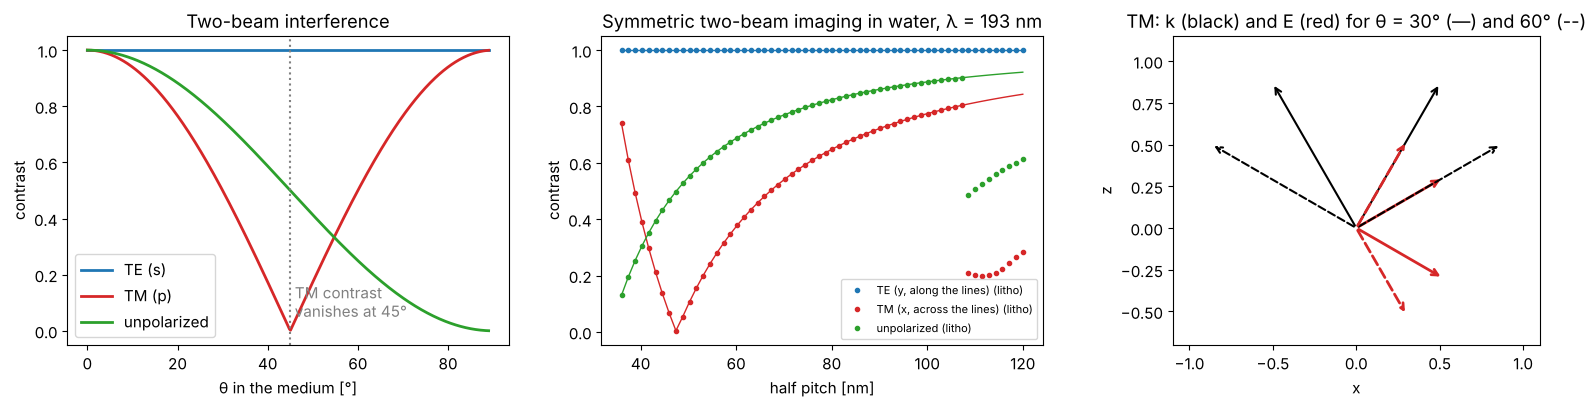

In [2]:
theta = np.radians(np.linspace(0, 89, 400))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for pol, label, c in (("TE", "TE (s)", "C0"), ("TM", "TM (p)", "C3"), ("unpolarized", "unpolarized", "C2")):
    axes[0].plot(np.degrees(theta), two_beam_contrast(theta, pol), color=c, lw=2, label=label)
axes[0].axvline(45, color="gray", ls=":")
axes[0].text(46, 0.05, "TM contrast\nvanishes at 45°", color="gray")
axes[0].set_xlabel("θ in the medium [°]"); axes[0].set_ylabel("contrast"); axes[0].legend()
axes[0].set_title("Two-beam interference")

hp = np.linspace(36, 120, 60)
for pol, label, c in POLS:
    V = []
    for h in hp:
        sim = LithoSimulation(MaskLayout.lines_spaces(4*h, 2*h), ThinMask(-1.0),
                              Illumination.coherent(polarization=pol), water)
        V.append(metrics.contrast(sim.image(np.linspace(-2*h, 2*h, 201))))
    axes[1].plot(hp, V, "o", ms=3, color=c, label=label + " (litho)")
th_hp = np.arcsin(wl/(4*hp*n_w))
for pol, c in (("TE", "C0"), ("TM", "C3"), ("unpolarized", "C2")):
    axes[1].plot(hp, two_beam_contrast(th_hp, pol), "-", color=c, lw=1)
axes[1].set_xlabel("half pitch [nm]"); axes[1].set_ylabel("contrast")
axes[1].set_title(f"Symmetric two-beam imaging in water, λ = {wl:.0f} nm")
axes[1].legend(fontsize=8)

# field vectors of the two TM waves at 30° and 60°
for t, ls in ((30, "-"), (60, "--")):
    tr = np.radians(t)
    for sgn in (+1, -1):
        k = np.array([sgn*np.sin(tr), np.cos(tr)])
        E = np.array([np.cos(tr), -sgn*np.sin(tr)])
        axes[2].annotate("", xy=k, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="k", lw=1.5, ls=ls))
        axes[2].annotate("", xy=0.6*E, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="C3", lw=2, ls=ls))
axes[2].set_xlim(-1.1, 1.1); axes[2].set_ylim(-0.7, 1.15); axes[2].set_aspect("equal")
axes[2].set_xlabel("x"); axes[2].set_ylabel("z")
axes[2].set_title("TM: k (black) and E (red) for θ = 30° (—) and 60° (--)")
fig.tight_layout()

## 2. Mask, sources and polarization in the pupil

A binary mask with 40 nm lines and 40 nm spaces (pitch 80 nm) has the
diffraction orders $c_m = -\tfrac12\,\mathrm{sinc}(m/2)$ plus $\tfrac12$ for $m = 0$
(`MaskLayout.region_coefficients()` gives the Fourier coefficients of the
lines analytically). With $\lambda/p = 2.41 > \mathrm{NA}$, normal incidence
cannot transmit any first order. An off-axis source point at $s_x$ shifts
the orders by $\mathrm{NA}\,s_x$ in the pupil; for
$s_x = \lambda/(2p\,\mathrm{NA}) = 0.89$ the orders 0 and $-1$ sit
symmetrically at the pupil edge: dipole illumination. The pupil fill
(bottom right) shows where the orders of all source points of the dipole
land in the pupil.

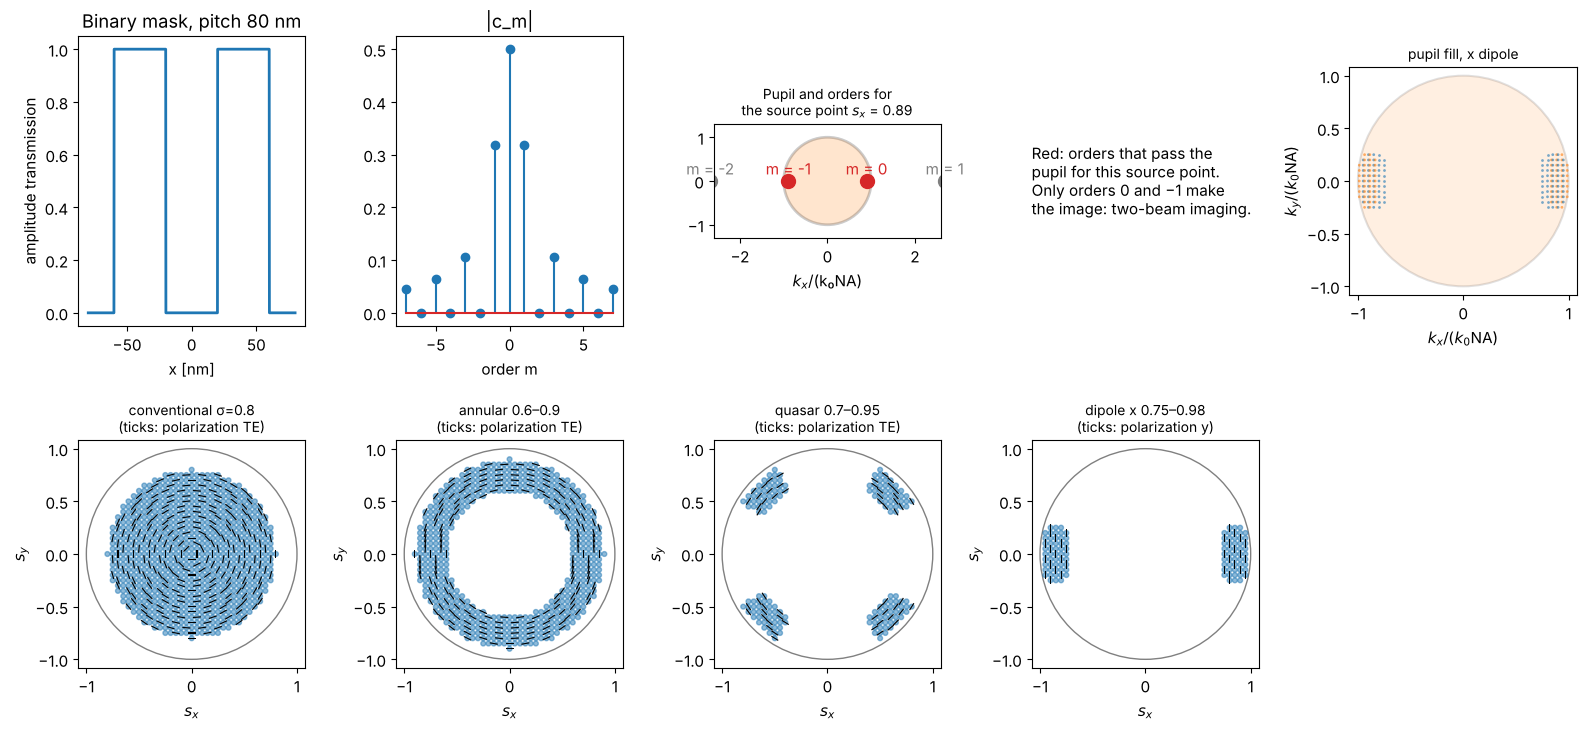

In [3]:
pitch = 80.0
ls80 = MaskLayout.lines_spaces(pitch, pitch/2)
sources = {
    "conventional σ=0.8": Illumination.conventional(0.8, n_samples=41, polarization="TE"),
    "annular 0.6–0.9": Illumination.annular(0.9, 0.6, n_samples=41, polarization="TE"),
    "quasar 0.7–0.95": Illumination.quasar(0.95, 0.7, opening_angle=30, n_samples=41, polarization="TE"),
    "dipole x 0.75–0.98": Illumination.dipole(0.98, 0.75, opening_angle=35, n_samples=41, polarization="y"),
}
m = np.arange(-7, 8)
c_m = ls80.region_coefficients(m, [0])["field"][0]  # binary: t = 1 in the spaces, 0 on the lines

fig = plt.figure(figsize=(16, 7.5))
ax = fig.add_subplot(2, 5, 1)
xx = np.linspace(-pitch, pitch, 1000)
ax.plot(xx, ls80.transmission(xx), lw=2)
ax.set_xlabel("x [nm]"); ax.set_title("Binary mask, pitch 80 nm"); ax.set_ylabel("amplitude transmission")
ax = fig.add_subplot(2, 5, 2)
ax.stem(m, np.abs(c_m)); ax.set_xlabel("order m"); ax.set_title("|c_m|")
ax = fig.add_subplot(2, 5, 3)
s_c = wl/(2*pitch*NA)
ax.add_patch(plt.Circle((0, 0), 1, fill=True, fc="C1", alpha=0.2, ec="k", lw=2))
for mm in (-2, -1, 0, 1):
    center = s_c + mm*wl/(pitch*NA)
    passes = abs(center) <= 1
    ax.plot(center, 0, "o", ms=10, color="C3" if passes else "gray")
    ax.text(center, 0.15, f"m = {mm}", ha="center", color="C3" if passes else "gray")
ax.set_xlim(-2.6, 2.6); ax.set_ylim(-1.3, 1.3); ax.set_aspect("equal")
ax.set_title(f"Pupil and orders for\nthe source point $s_x$ = {s_c:.2f}", fontsize=10); ax.set_xlabel("$k_x$/(k₀NA)")
ax = fig.add_subplot(2, 5, 4); ax.axis("off")
ax.text(0, 0.5, "Red: orders that pass the\npupil for this source point.\n"
        "Only orders 0 and −1 make\nthe image: two-beam imaging.", fontsize=11, va="center")
plot_pupil_fill(LithoSimulation(ls80, ThinMask.binary(), sources["dipole x 0.75–0.98"], water),
                ax=fig.add_subplot(2, 5, 5), title="pupil fill, x dipole")
for i, (name, src) in enumerate(sources.items()):
    plot_source(src, ax=fig.add_subplot(2, 5, 6 + i), every=3,
                title=name + f"\n(ticks: polarization {src.polarization})")
fig.tight_layout()

## 3. Aerial images at $k_1 = 0.28$: 40 nm lines and spaces

With the $x$ dipole, $y$ polarization is TE for (nearly) all diffraction
orders, $x$ polarization TM. At NA 1.35 the two interfering orders travel at
about $\pm 57°$ in water, beyond 45°: the TM image is *reversed* (bright where
the lines are dark). Added incoherently to the TE image it eats up most of
the contrast of unpolarized light. The scalar model knows nothing of this;
it gives the same image for every polarization.

The images are normalized to the open frame (the intensity of a clear
mask), as all images of `LithoSimulation`; NILS is evaluated at the nominal
line edges (`LithoSimulation.nils()`).

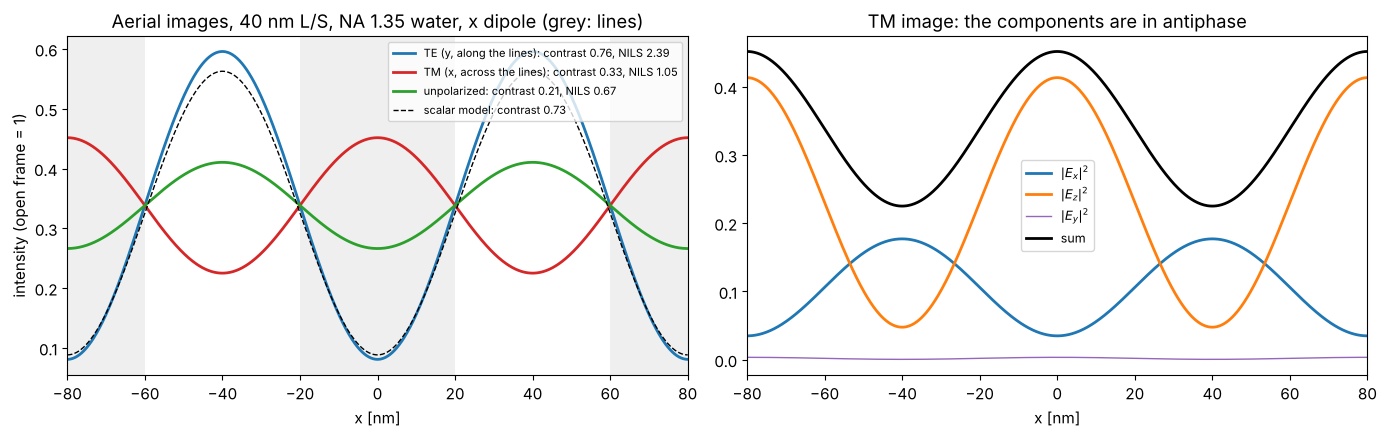

In [4]:
dip = sources["dipole x 0.75–0.98"]
sim = LithoSimulation(ls80, ThinMask.binary(), dip, water)
x = np.linspace(-pitch, pitch, 801)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for pol, label, c in POLS:
    s = sim.with_(illumination=dip.with_polarization(pol))
    I = s.image(x)
    plot_image(s, x, I, ax=axes[0], show_mask=(pol == "y"), color=c, lw=2,
               label=f"{label}: contrast {metrics.contrast(I):.2f}, NILS {s.nils():.2f}")
s_scalar = sim.with_(illumination=dip.with_polarization("unpolarized"), projector=water.with_(vectorial=False))
I_s = s_scalar.image(x)
axes[0].plot(x, I_s, "k--", lw=1, label=f"scalar model: contrast {metrics.contrast(I_s):.2f}")
axes[0].set_xlabel("x [nm]"); axes[0].set_ylabel("intensity (open frame = 1)")
axes[0].set_title("Aerial images, 40 nm L/S, NA 1.35 water, x dipole (grey: lines)")
axes[0].legend(fontsize=8, loc="upper right")

I_TM, I_xyz = sim.with_(illumination=dip.with_polarization("x")).image(x, return_components=True)
axes[1].plot(x, I_xyz[0], color="C0", lw=2, label="$|E_x|^2$")
axes[1].plot(x, I_xyz[2], color="C1", lw=2, label="$|E_z|^2$")
axes[1].plot(x, I_xyz[1], color="C4", lw=1, label="$|E_y|^2$")
axes[1].plot(x, I_TM, "k", lw=2, label="sum")
axes[1].set_xlabel("x [nm]"); axes[1].set_xlim(-pitch, pitch)
axes[1].set_title("TM image: the components are in antiphase")
axes[1].legend(fontsize=9)
fig.tight_layout()

Each field component on its own is modulated strongly, but $|E_x|^2$ and
$|E_z|^2$ peak at different places; the resist sees their sum.

The vectorial model contains the radiometric (obliquity) factor
$1/\sqrt{\cos\theta}$: a reduction lens concentrates the light of the mask
side onto oblique waves in the image space, which raises their amplitude
(as for the high NA focus in notebook 02). The open frame (the zeroth
order of each source point) gets the same factor, so it mostly cancels in
the normalized images. `Projector(..., obliquity=False)` switches it off.

## 4. Through pitch

Contrast and NILS (normalized image log slope at the nominal line edge,
$w\,|\partial_x \ln I|$, a measure of exposure latitude; resists need about
NILS ≳ 1.5 to 2) against the half pitch, for the dipole adapted to each
pitch (`Illumination.dipole_for_pitch()`: $s_c = \lambda/(2p\,\mathrm{NA})$,
poles from $s_c - 0.1$ to $s_c + 0.1$) and for a fixed annular source.

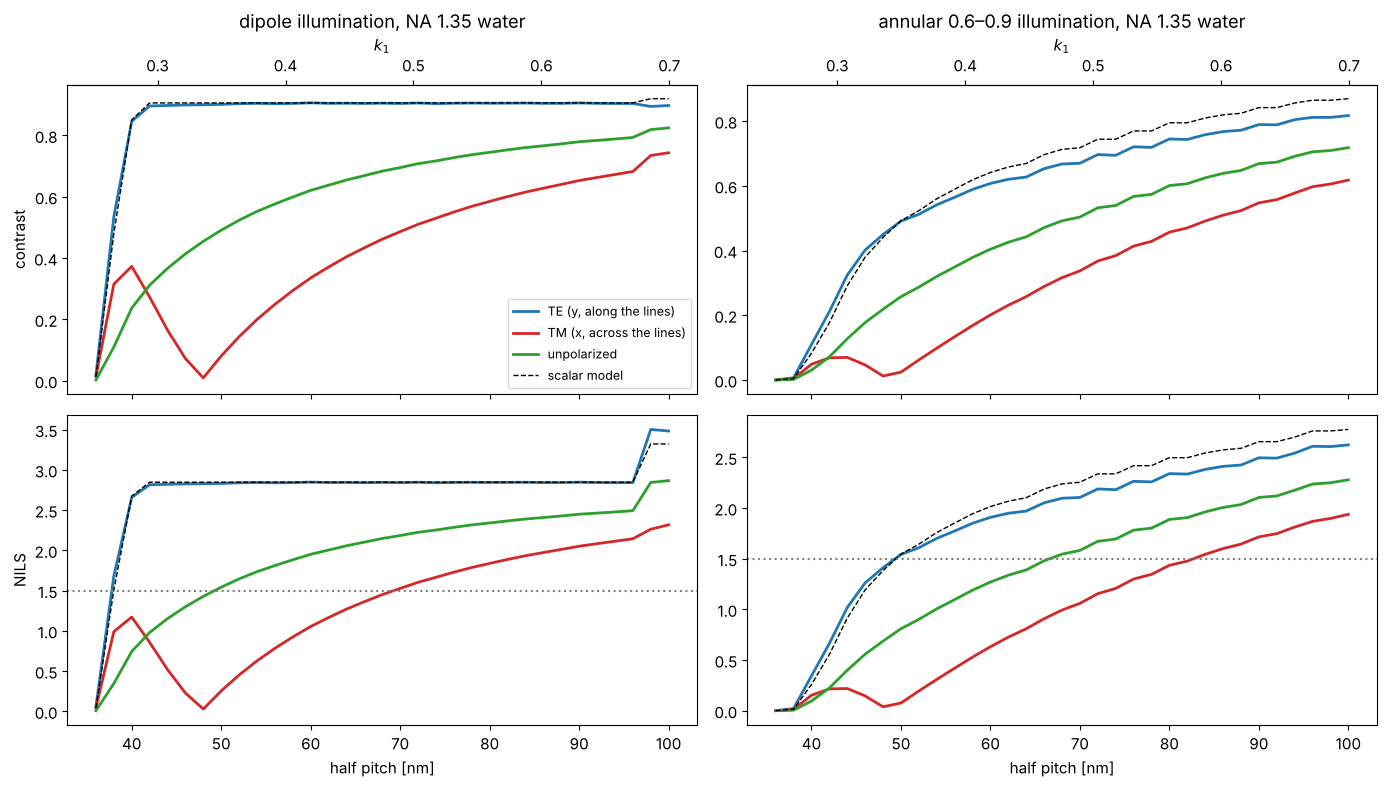

In [5]:
hp_vals = np.arange(36, 101, 2.0)
results = {}
for src_name in ("dipole", "annular 0.6–0.9"):
    for pol, label, c in POLS + [("scalar", "scalar model", "k")]:
        V, N_ = [], []
        for h in hp_vals:
            p = 2*h
            ill = (Illumination.dipole_for_pitch(p, wl, NA, n_samples=61) if src_name == "dipole"
                   else sources[src_name])
            ill = ill.with_polarization("unpolarized" if pol == "scalar" else pol)
            proj = water.with_(vectorial=(pol != "scalar"))
            s = LithoSimulation(MaskLayout.lines_spaces(p, h), ThinMask.binary(), ill, proj)
            u, I = s.cut(401)
            V.append(metrics.contrast(I)); N_.append(metrics.nils(u, I, h/2, h))
        results[(src_name, pol)] = (np.array(V), np.array(N_))

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for j, src_name in enumerate(("dipole", "annular 0.6–0.9")):
    for pol, label, c in POLS + [("scalar", "scalar model", "k")]:
        V, N_ = results[(src_name, pol)]
        ls = "--" if pol == "scalar" else "-"
        axes[0, j].plot(hp_vals, V, ls, color=c, lw=2 if pol != "scalar" else 1, label=label)
        axes[1, j].plot(hp_vals, N_, ls, color=c, lw=2 if pol != "scalar" else 1, label=label)
    axes[0, j].set_title(f"{src_name} illumination, NA 1.35 water")
    axes[1, j].axhline(1.5, color="gray", ls=":")
    axes[1, j].set_xlabel("half pitch [nm]")
    sec = axes[0, j].secondary_xaxis("top", functions=(lambda h: h*NA/wl, lambda k1: k1*wl/NA))
    sec.set_xlabel("$k_1$")
axes[0, 0].set_ylabel("contrast"); axes[1, 0].set_ylabel("NILS")
axes[0, 0].legend(fontsize=9)
fig.tight_layout()

(The step of the dipole curves near 97 nm half pitch is the onset of
three-beam imaging: the order $+1$ starts to pass through the pupil.)

Towards the resolution limit TE keeps a high contrast while TM collapses and
even reverses; the scalar model overestimates the contrast of unpolarized
light substantially. This is why hyper-NA immersion scanners use polarized
illumination (TE for the dominant line direction, or azimuthal polarization
for annular and quasar sources).

## 5. Why dry lithography got away with unpolarized light

The same $k_1$ at a smaller NA means smaller angles in the image space. We
compare (all at $k_1 = 0.30$, adapted dipole) dry systems with NA 0.75 and
0.93 and immersion systems with NA 1.2 and 1.35. Plotted: the contrast of
TE, TM and unpolarized light against NA (sweeping dry NA from 0.5 to 0.95 and
immersion NA from 0.5 to 1.35).

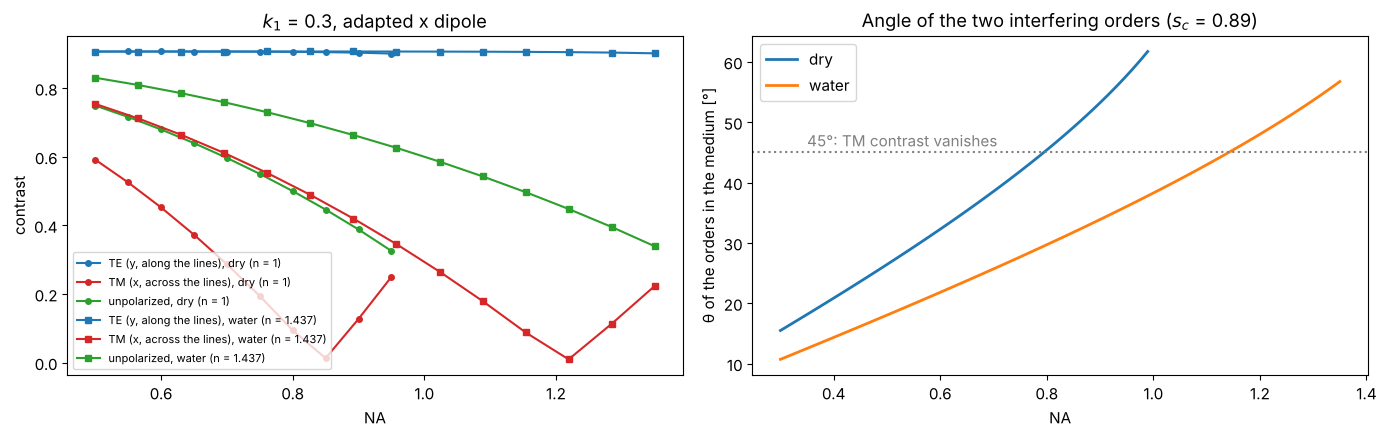

In [6]:
k1 = 0.30
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for n_med, name, NA_range, mk in ((1.0, "dry (n = 1)", np.linspace(0.5, 0.95, 10), "o"),
                                  (n_w, "water (n = 1.437)", np.linspace(0.5, 1.35, 14), "s")):
    for pol, label, c in POLS:
        V = []
        for NA_ in NA_range:
            h = k1*wl/NA_; p = 2*h
            s = LithoSimulation(MaskLayout.lines_spaces(p, h), ThinMask.binary(),
                                Illumination.dipole_for_pitch(p, wl, NA_, n_samples=61, polarization=pol),
                                Projector(NA_, wl, n_med))
            V.append(metrics.contrast(s.cut(201)[1]))
        axes[0].plot(NA_range, V, mk + "-", color=c, ms=4, label=f"{label}, {name}")
axes[0].set_xlabel("NA"); axes[0].set_ylabel("contrast"); axes[0].set_title(f"$k_1$ = {k1}, adapted x dipole")
axes[0].legend(fontsize=8)
# angle of the interfering orders in the medium
NA_ax = np.linspace(0.3, 1.35, 100)
for n_med, name in ((1.0, "dry"), (n_w, "water")):
    sel = NA_ax <= n_med*0.999
    axes[1].plot(NA_ax[sel], np.degrees(np.arcsin(0.89*NA_ax[sel]/n_med)), lw=2, label=name)
axes[1].axhline(45, color="gray", ls=":"); axes[1].text(0.35, 46, "45°: TM contrast vanishes", color="gray")
axes[1].set_xlabel("NA"); axes[1].set_ylabel("θ of the orders in the medium [°]")
axes[1].set_title("Angle of the two interfering orders ($s_c$ = 0.89)")
axes[1].legend()
fig.tight_layout()

At the same NA, a higher refractive index of the image space makes the
angles smaller ($\sin\theta = \mathrm{NA}\,s/n$); a dry system cannot exceed
NA ≈ 0.93, where the orders still travel at about 56°. In water at NA 1.35
the angles are again as large, now in water, which is why the polarization
problem came back with immersion. (Inside the resist, $n \approx 1.7$, the
angles are smaller again, and TE and TM are transmitted differently at the
water-resist interface; `litho.WaferStack` computes images in the resist,
see notebook 32.)

## 6. Defocus

Contrast through focus for 45 nm L/S with the adapted dipole: TE keeps its
advantage over the whole focus range.

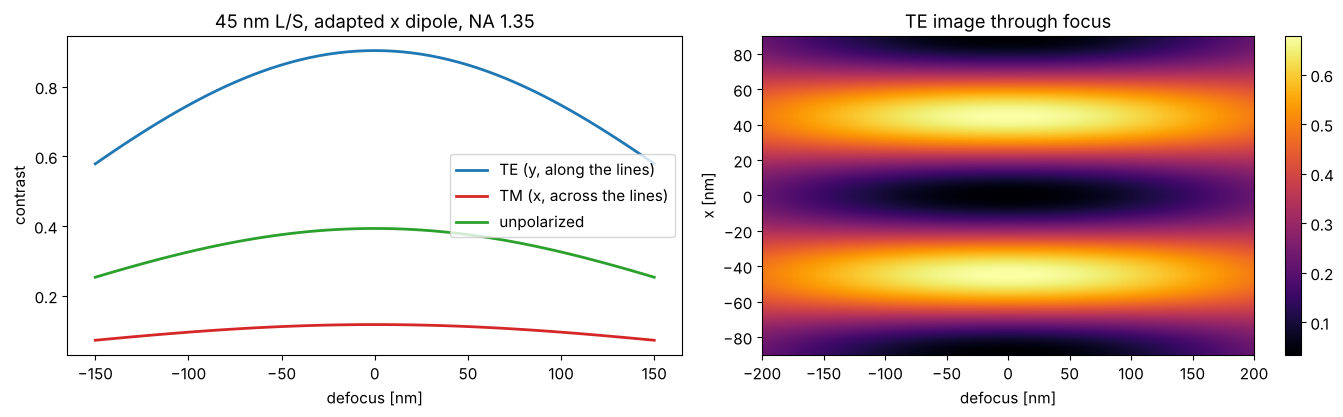

In [7]:
h = 45.0; p = 2*h
s45 = LithoSimulation(MaskLayout.lines_spaces(p, h), ThinMask.binary(),
                      Illumination.dipole_for_pitch(p, wl, NA, n_samples=61), water)
dz = np.linspace(-150, 150, 61)
xs = np.linspace(-p/2, p/2, 201)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for pol, label, c in POLS:
    s = s45.with_(illumination=s45.illumination.with_polarization(pol))
    V = [metrics.contrast(I) for I in s.through_focus(xs, dz)]
    axes[0].plot(dz, V, color=c, lw=2, label=label)
axes[0].set_xlabel("defocus [nm]"); axes[0].set_ylabel("contrast"); axes[0].legend()
axes[0].set_title("45 nm L/S, adapted x dipole, NA 1.35")
# x-z image of the TE case
zz = np.linspace(-200, 200, 81)
s_TE = s45.with_(illumination=s45.illumination.with_polarization("y"))
xz = s_TE.through_focus(np.linspace(-p, p, 161), zz)
im = axes[1].imshow(xz.T, extent=[zz[0], zz[-1], -p, p], aspect="auto", cmap="inferno")
axes[1].set_xlabel("defocus [nm]"); axes[1].set_ylabel("x [nm]"); axes[1].set_title("TE image through focus")
fig.colorbar(im, ax=axes[1])
fig.tight_layout()

With a symmetric dipole whose poles sit exactly at $s_c$, the two orders pass
the pupil symmetrically and their defocus phases are equal, so the image
would not depend on focus at all; the finite width of the poles causes the
loss of contrast seen here.

## 7. How well polarized must the illumination be?

Real illuminators deliver partially polarized light. The quality is measured
as the intensity in the preferred state, IPS: the fraction of light an
ideal analyzer for the desired (here: $y$, TE) polarization would pass. Light
with the degree of polarization $P$ in the preferred state $y$ has the Stokes
vector $S = (1, -P, 0, 0)$ and $\mathrm{IPS} = (1 + P)/2$. The
illumination takes it as `polarization="y", dop=P` (a fraction $P$ in the
state $y$, the rest unpolarized), or directly as the Stokes vector, which is
split into two incoherent Jones vectors (`polarization.jones_from_stokes()`).

dop = 0.8 vs Stokes vector (1, -0.8, 0, 0): max difference 1.3322676295501878e-15
IPS = 0.9: NILS = 2.28 (TE: 2.66, unpolarized: 0.74)
IPS = 0.95: NILS = 2.47 (TE: 2.66, unpolarized: 0.74)


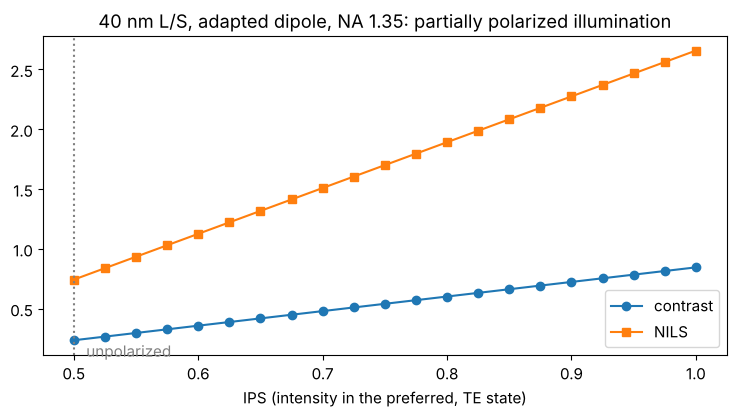

In [8]:
h = 40.0; p = 2*h
s40 = LithoSimulation(MaskLayout.lines_spaces(p, h), ThinMask.binary(),
                      Illumination.dipole_for_pitch(p, wl, NA, n_samples=61), water)
xs = np.linspace(-p/2, p/2, 401)
P_vals = np.linspace(0, 1, 21)
ips, V, Nl = [], [], []
for P in P_vals:
    ips.append(IPS(np.array([1.0, -P, 0.0, 0.0]), J_V))
    s = s40.with_(illumination=s40.illumination.with_polarization("y", dop=P))
    I = s.image(xs)
    V.append(metrics.contrast(I)); Nl.append(metrics.nils(xs, I, h/2, h))
# the same with the Stokes vector, as a check:
I_S = s40.with_(illumination=s40.illumination.with_polarization(np.array([1.0, -0.8, 0.0, 0.0]))).image(xs)
print("dop = 0.8 vs Stokes vector (1, -0.8, 0, 0): max difference",
      np.abs(I_S - s40.with_(illumination=s40.illumination.with_polarization("y", dop=0.8)).image(xs)).max())

fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(ips, V, "o-", label="contrast")
ax.plot(ips, Nl, "s-", label="NILS")
ax.set_xlabel("IPS (intensity in the preferred, TE state)")
ax.set_title("40 nm L/S, adapted dipole, NA 1.35: partially polarized illumination")
ax.axvline(0.5, color="gray", ls=":"); ax.text(0.51, 0.1, "unpolarized", color="gray")
ax.legend(); fig.tight_layout()
for target in (0.9, 0.95):
    print(f"IPS = {target}: NILS = {np.interp(target, ips, Nl):.2f} "
          f"(TE: {Nl[-1]:.2f}, unpolarized: {Nl[0]:.2f})")

Contrast and NILS fall linearly with the TM content, because the TM image is
reversed: every percent of TM light subtracts from the TE image.

## 8. Attenuated phase shift mask

An attenuated PSM transmits 6 % of the intensity through the "dark" lines,
with a phase shift of π: `ThinMask.att_psm(0.06)`. With the dipole it gives
a higher NILS than the binary mask at the same polarization.

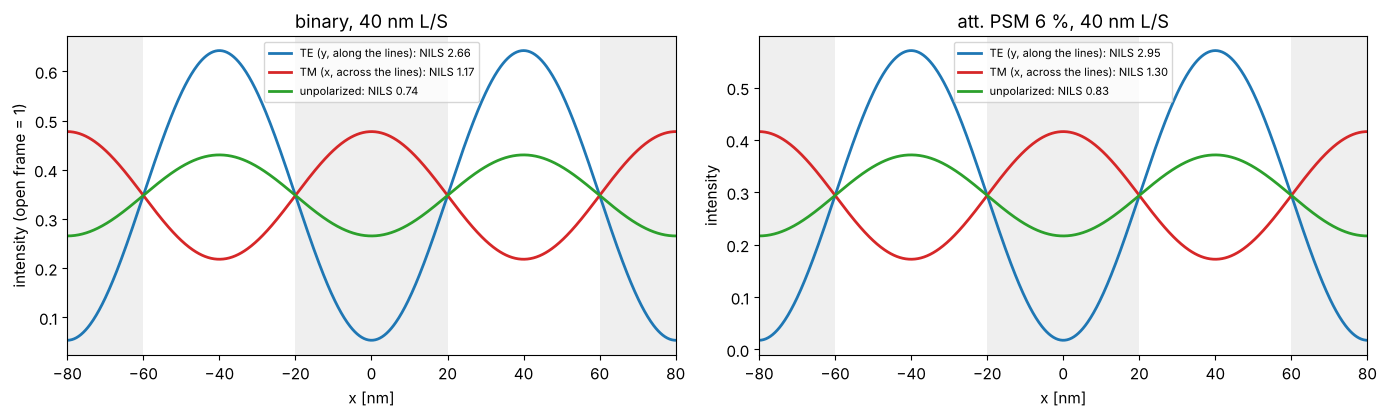

In [9]:
xs = np.linspace(-p, p, 801)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for ax, stack in zip(axes, (ThinMask.binary(), ThinMask.att_psm(0.06))):
    for pol, label, c in POLS:
        s = s40.with_(stack=stack, illumination=s40.illumination.with_polarization(pol))
        plot_image(s, xs, s.image(xs), ax=ax, show_mask=(pol == "y"), color=c, lw=2,
                   label=f"{label}: NILS {s.nils():.2f}")
    ax.set_title(f"{stack.name}, 40 nm L/S"); ax.set_xlabel("x [nm]"); ax.legend(fontsize=8)
axes[0].set_ylabel("intensity (open frame = 1)")
fig.tight_layout()

## 9. Two-dimensional masks: contact holes

`LithoSimulation` sums the diffraction orders of any periodic layout
directly on the requested grid, for 1D and 2D masks alike. First a
consistency check against `vectorial_imaging.image_1d()`. Then an array of
50 nm contact holes at 110 nm pitch (dark field mask: holes transmit),
illuminated by a quasar or annular source with azimuthal (TE), radial (TM)
and no polarization. For holes, both directions matter. With the annular
source azimuthal polarization wins clearly; with the quasar the
polarizations differ little, because the orders of a pole at 45° interfere
in pairs along x, y and the diagonals, and the azimuthal polarization is TE
only for some of these pairs (notebook 32, section 6, shows a case where
radial polarization is better). The cyan
contour is the printed hole for the threshold 0.3 at the dose that sizes
the azimuthally polarized case to 50 nm (`dose_to_size()`).

max |litho - image_1d| / max: 4.178115259160627e-16


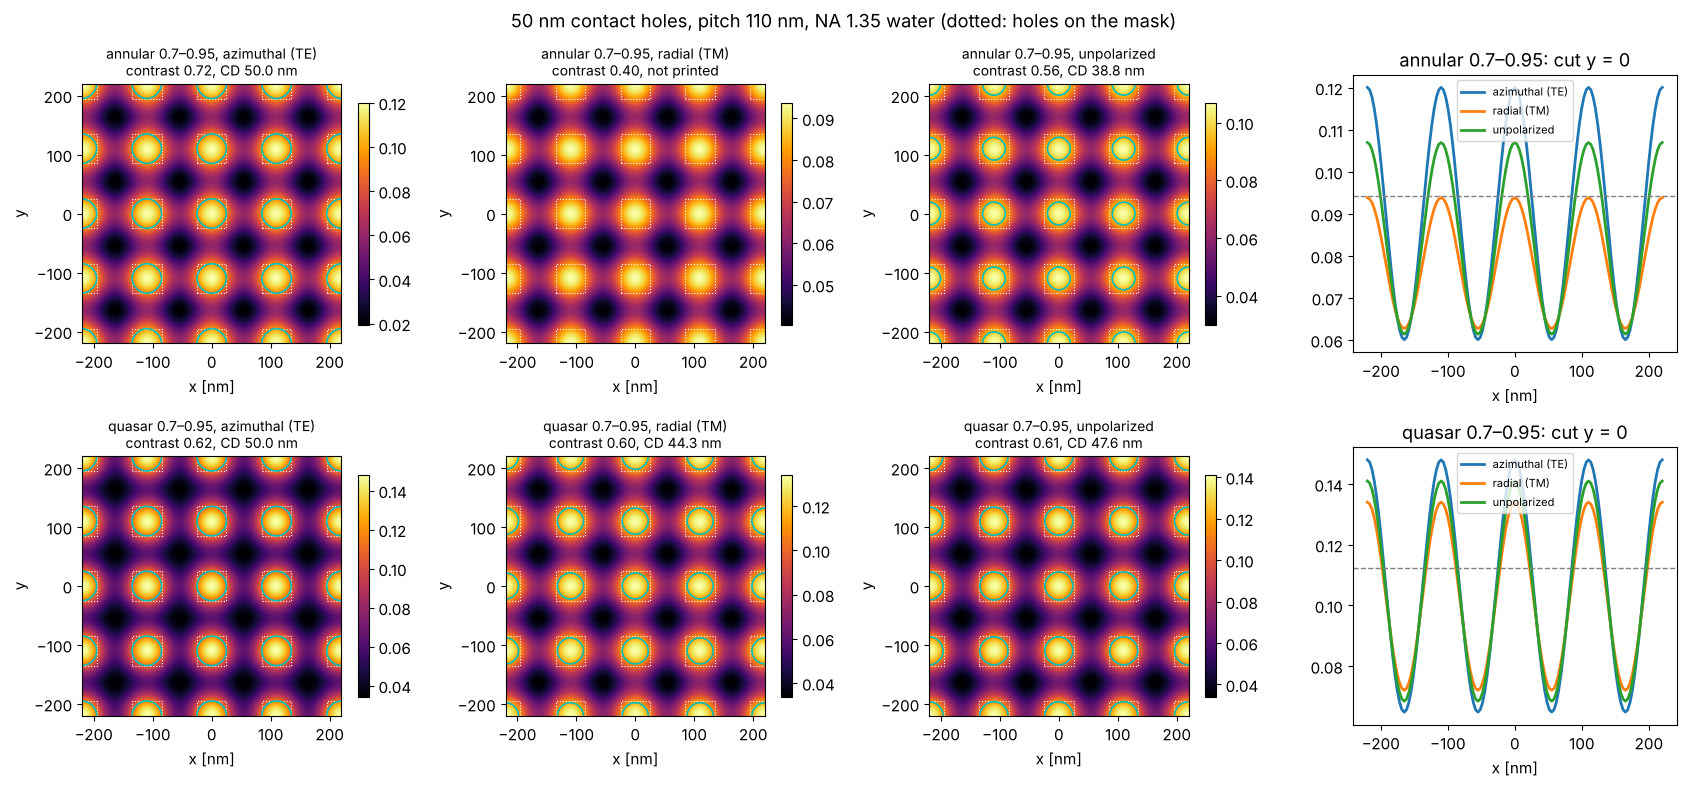

In [10]:
src = Illumination.dipole(0.98, 0.65, n_samples=31)
I_toolbox = LithoSimulation(MaskLayout.lines_spaces(90.0, 45.0), ThinMask.binary(), src, water,
                            normalize=False).image(xs)
I_ref = image_1d(xs, 90.0, lines_spaces_orders(90.0, 45.0, 6), NA, wl, src.points(), "unpolarized", n=n_w)
print("max |litho - image_1d| / max:", np.abs(I_toolbox - I_ref).max()/I_ref.max())

holes = MaskLayout.contact_holes(110.0, 50.0)
xc = np.linspace(-220, 220, 129)
srcs = {"annular 0.7–0.95": Illumination.annular(0.95, 0.7, n_samples=31),
        "quasar 0.7–0.95": Illumination.quasar(0.95, 0.7, opening_angle=30, n_samples=31)}
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for i, (sname, s0) in enumerate(srcs.items()):
    s_hole = LithoSimulation(holes, ThinMask.binary(), s0.with_polarization("TE"), water)
    D = s_hole.dose_to_size(50.0, threshold=0.3)
    cuts = {}
    for j, (pol, label) in enumerate((("TE", "azimuthal (TE)"), ("TM", "radial (TM)"), ("unpolarized", "unpolarized"))):
        s = s_hole.with_(illumination=s0.with_polarization(pol))
        I = s.image(xc, xc)
        cuts[label] = I[len(xc)//2]
        plot_image(s, xc, I, xc, ax=axes[i, j], threshold=0.3, dose=D)
        cd = s.cd(0.3, D)
        cd_text = "not printed" if np.isnan(cd) else f"CD {cd:.1f} nm"
        axes[i, j].set_title(f"{sname}, {label}\ncontrast {metrics.contrast(I):.2f}, {cd_text}",
                             fontsize=10)
        axes[i, j].set_xlabel("x [nm]")
    for label, cut in cuts.items():
        axes[i, 3].plot(xc, cut, lw=2, label=label)
    axes[i, 3].axhline(0.3/D, color="gray", ls="--", lw=1)
    axes[i, 3].set_title(f"{sname}: cut y = 0"); axes[i, 3].set_xlabel("x [nm]"); axes[i, 3].legend(fontsize=8)
fig.suptitle("50 nm contact holes, pitch 110 nm, NA 1.35 water (dotted: holes on the mask)")
fig.tight_layout()

## 10. Process windows: what polarization buys

Contrast and NILS translate into process windows. For 45 nm L/S with the
adapted dipole, the focus-exposure matrix (`LithoSimulation.fem()`, threshold
resist with the threshold 0.3 of the open frame, doses relative to the dose
to size at best focus) gives Bossung curves (CD vs. focus for several
doses) and the window in which the CD stays within ±10 % of 45 nm. Its
exposure latitude vs. depth of focus (`metrics.el_dof()`) shows how much
dose and focus error TE illumination tolerates compared with unpolarized
light.

TE (y, along the lines): EL at best focus 28.3 %, DOF at 5 % EL 510 nm


unpolarized: EL at best focus 12.3 %, DOF at 5 % EL 390 nm


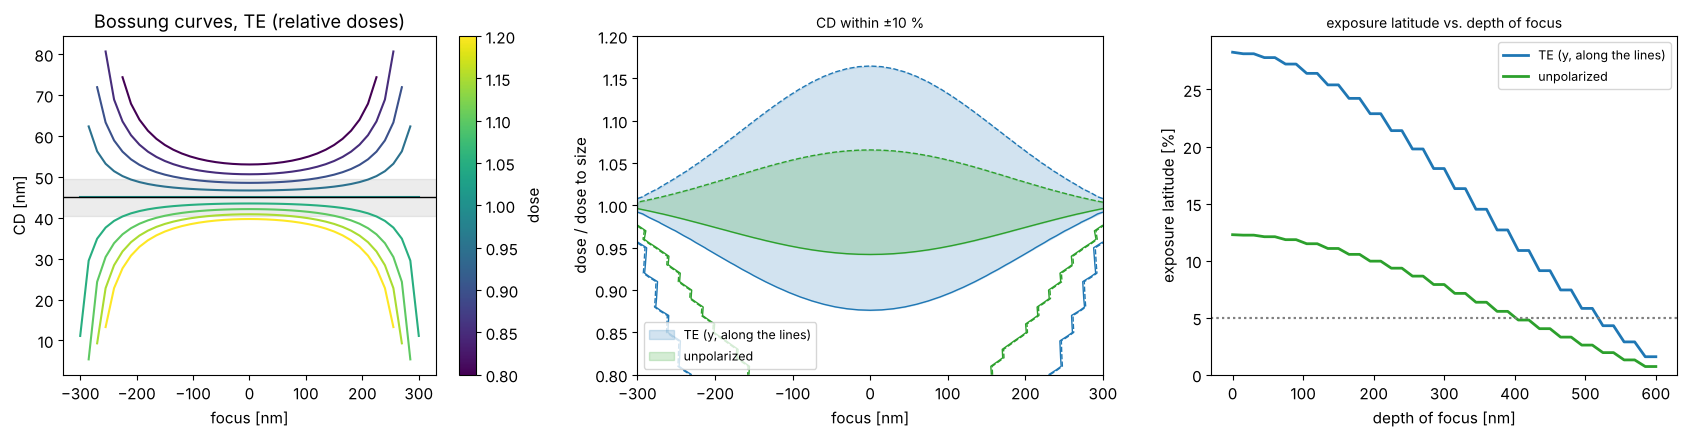

In [11]:
h = 45.0
foci = np.linspace(-300, 300, 41)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for pol, label, c in POLS[::2]:
    s = s45.with_(illumination=s45.illumination.with_polarization(pol))
    D0 = s.dose_to_size(h, threshold=0.3)
    doses = D0*np.linspace(0.8, 1.2, 41)
    cd = s.fem(foci, doses, threshold=0.3)
    if pol == "y":
        plot_bossung(foci, doses/D0, cd, ax=axes[0], cd_target=h, every=5)
        axes[0].set_title("Bossung curves, TE (relative doses)")
        axes[0].set_xlabel("focus [nm]"); axes[0].set_ylabel("CD [nm]")
    dof, el = plot_process_window(foci, doses/D0, cd, h, 0.1, axes=axes[1:], color=c, label=label,
                                  el_min=0.05)
    print(f"{label}: EL at best focus {100*el[0]:.1f} %, DOF at 5 % EL {metrics.dof_at_el(dof, el, 0.05):.0f} nm")
axes[1].set_xlabel("focus [nm]"); axes[1].set_ylabel("dose / dose to size"); axes[1].legend(fontsize=9)
axes[2].set_xlabel("depth of focus [nm]"); axes[2].legend(fontsize=9)
axes[2].set_title("exposure latitude vs. depth of focus", fontsize=10)
fig.tight_layout()

## Summary

- At hyper-NA the polarization decides whether lines and spaces near
  $k_1 = 0.28$ can be printed: TE keeps the contrast, TM loses it (and
  reverses beyond 45° in the medium), unpolarized light ends up in between,
  much lower than the scalar model predicts.
- The effect comes from the angle in the image space medium; it was
  negligible for dry NA ≲ 0.7 and returns with immersion.
- Partially polarized illumination is described by a degree of
  polarization or a Stokes vector; NILS falls linearly with the TM content,
  so IPS values above 90 % matter.
- TE illumination enlarges the process window (exposure latitude and depth
  of focus) substantially.
- `pyoptics.litho` sums the diffraction orders of periodic 1D and 2D
  layouts exactly and agrees with `vectorial_imaging.image_1d()`; notebook
  32 continues with more sources, masks, mask stacks and resist stacks.